# Fullset FP2026.1: fluxes and meteo, 2016-2026.09

**notebook version**: `1` (26 Oct 2026)

## ℹ️ About this notebook

This notebook builds the fullset of the release **FP2026.1** (1 January 2016 to 30 September 2026).
It joins, on the timestamp:

| Source | What it adds |
|---|---|
| `20_MERGE_DATA/IRGA72/22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09` | Level-1 fluxes of the `IRGA72` runs and the meteo of `10_METEO/30_PRODUCTS/99` |
| `01_FPPC_IRGA72_NEE_2016-2026.09` | `NEE`: quality flags, storage term, USTAR scenarios, gap-filled series and their uncertainty |
| `11_FPPC_IRGA72_LE_2016-2026.09` | `LE`: quality flags, gap-filled series, and `ET` derived from them |
| `15_FPPC_IRGA72_H_2016-2026.09` | `H`: quality flags and gap-filled series |

Each flux notebook writes only the columns it adds, so every column of the fullset comes from exactly
one source. The columns that more than one flux notebook computes (potential radiation and the
day/night flags) are checked to be identical and kept once.

The fullset holds every available column. It is not yet the published file: which variables the
release carries, and under which names, is decided separately (`PLAN.md`, section 3.3).

## ⚙️ Settings

In [1]:
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
INPUTFILE = rf"{DATADIR}\20_MERGE_DATA\IRGA72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet"
FLUXDIR = rf"{DATADIR}\30_FLUX_PROCESSING_CHAIN\34_IRGA72_2016-2024"
FLUXFILES = {
    'NEE': rf"{FLUXDIR}\01_FPPC_IRGA72_NEE_2016-2026.09.parquet",
    'LE': rf"{FLUXDIR}\11_FPPC_IRGA72_LE_2016-2026.09.parquet",
    'H': rf"{FLUXDIR}\15_FPPC_IRGA72_H_2016-2026.09.parquet",
}
PERIOD_START, PERIOD_END = '2016-01-01 00:15', '2026-09-30 23:45'

OUTNAME = "41_FULLSET_FP2026.1_2016-2026.09"  # same name as this notebook
OUTPATH = rf"{DATADIR}\40_FULLSET"

# Conversion of half-hourly values to sums
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # NEE, umol m-2 s-1 -> gC m-2 per half-hour
WM2_TO_MJ = 1800 * 1e-6  # LE and H, W m-2 -> MJ m-2 per half-hour

In [2]:
from datetime import datetime
import importlib.metadata

import diive as dv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-26 16:09:00
diive version: v0.93.0


## 📂 Load data

In [3]:
inp = dv.load_parquet(filepath=INPUTFILE)
fluxes = {k: dv.load_parquet(filepath=v) for k, v in FLUXFILES.items()}

# Every file covers the full period on the same timestamps.
expected = pd.date_range(PERIOD_START, PERIOD_END, freq='30min')
for name, frame in {'input': inp, **fluxes}.items():
    assert frame.index.equals(expected), f"{name} does not run from {PERIOD_START} to {PERIOD_END} in 30 min"
    print(f"{name:>6}: {frame.shape[0]:,} records x {frame.shape[1]} columns")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRG
A72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet (0.269 seconds).

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_PROCESSIN
G_CHAIN\34_IRGA72_2016-2024\01_FPPC_IRGA72_NEE_2016-2026.09.parquet (0.048 seconds).

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_PROCESSIN
G_CHAIN\34_IRGA72_2016-2024\11_FPPC_IRGA72_LE_2016-2026.09.parquet (0.026 seconds).

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_PROCESSIN
G_CHAIN\34_IRGA72_2016-2024\15_FPPC_IRGA72_H_2016-2026.09.parquet (0.028 seconds).

 input: 188,448 records x 348 columns
   NEE: 188,448 records x 76 columns
    LE: 188,448 records x 45 columns
     H: 188,448 records x 43 columns


## Join

The input carries `SW_IN_POT` from the EddyPro output. It runs about 15 minutes ahead of the
timestamp (`TIMESTAMP_MIDDLE`), as if it were computed for the end of each half-hour. The flux
notebooks compute their own `SW_IN_POT` for the middle of each half-hour, from which their day and
night flags come. The fullset keeps that one as `SW_IN_POT` and the EddyPro one as
`SW_IN_POT_EDDYPRO`.

Apart from that, a flux output must not contain an input column. A column that several flux outputs contain must be
identical in all of them, and is kept from the first.

In [4]:
# EddyPro's potential radiation, renamed so the one of the flux chain takes its name.
inp = inp.rename(columns={'SW_IN_POT': 'SW_IN_POT_EDDYPRO'})
_lead = (inp['SW_IN_POT_EDDYPRO'] - fluxes['NEE']['SW_IN_POT']).groupby(inp.index.hour).mean()
print(f"EddyPro minus chain SW_IN_POT, mean by hour of day: morning {_lead.loc[6:9].mean():+.1f}, "
      f"evening {_lead.loc[15:18].mean():+.1f} W m-2")

for name, frame in fluxes.items():
    clash = sorted(set(frame.columns) & set(inp.columns))
    assert not clash, f"{name} repeats input columns: {clash[:5]}"

SOURCE = {c: 'input' for c in inp.columns}
parts = [inp]
for name, frame in fluxes.items():
    new = []
    for c in frame.columns:
        if c in SOURCE:
            first = fluxes[SOURCE[c]][c]
            assert first.equals(frame[c]), f"{c} differs between {SOURCE[c]} and {name}"
            continue
        SOURCE[c] = name
        new.append(c)
    parts.append(frame[new])
fullset = pd.concat(parts, axis=1)
assert fullset.columns.is_unique
print(f"Fullset: {fullset.shape[0]:,} records x {fullset.shape[1]} columns")

EddyPro minus chain SW_IN_POT, mean by hour of day: morning +32.1, evening -31.8 W m-2
Fullset: 188,448 records x 506 columns


### 📋 Table: columns per source

In [5]:
_src = pd.Series(SOURCE)
display(_src.value_counts().reindex(['input', *FLUXFILES]).rename('columns').to_frame())

,columns
input,348
NEE,76
LE,42
H,40


## Main gap-filled fluxes

The gap-filled series of each flux and method, with the share of measured records per year. `NEE`
uses the CUT_50 scenario; `LE`, `ET` and `H` are not USTAR-filtered (scenario `CUT_NONE`).

In [6]:
# Gap-filled column, its fill flag, and the gain to turn a half-hour into a sum.
MAIN = {
    'NEE (gC m-2)': ('NEE_L3.1_L3.3_CUT_50_QCF_gf{m}', UMOL_TO_GC),
    'LE (MJ m-2)': ('LE_L3.1_L3.3_CUT_NONE_QCF_gf{m}', WM2_TO_MJ),
    'ET (mm)': ('ET_L3.1_L3.3_CUT_NONE_QCF_gf{m}', 1),
    'H (MJ m-2)': ('H_L3.1_L3.3_CUT_NONE_QCF_gf{m}', WM2_TO_MJ),
}
METHODS = {'XGBoost': 'XG', 'MDS': 'MDS'}
for _var, (_pattern, _gain) in MAIN.items():
    for _m in METHODS.values():
        _col = _pattern.format(m=_m)
        assert _col in fullset.columns, f"{_col} is not in the fullset"
        assert fullset[_col].notna().all(), f"{_col} has gaps"

### 📋 Table: annual sums per method

In [7]:
_year = fullset.index.year
_rows = {}
for _var, (_pattern, _gain) in MAIN.items():
    for _mname, _m in METHODS.items():
        _rows[(_var, _mname)] = (fullset[_pattern.format(m=_m)] * _gain).groupby(_year).sum()
ANNUAL = pd.DataFrame(_rows).T
ANNUAL.index.names = ['variable', 'method']
ANNUAL.columns.name = 'year'
print(f"Annual sums; {_year.max()} ends on {fullset.index[-1]:%d %B}.")
display(ANNUAL.round(0).astype(int))

Annual sums; 2026 ends on 30 September.


year                  2016  2017  2018  2019  2020  2021  2022  2023  2024  \
variable     method                                                          
NEE (gC m-2) XGBoost  -139    63  -108  -272  -280   -26   -27     9   -29   
             MDS      -290     9  -211  -318  -346  -107  -108   -20   -48   
LE (MJ m-2)  XGBoost  1494  1527  1422  1483  1493  1356  1538  1601  1555   
             MDS      1588  1526  1433  1450  1479  1351  1529  1595  1549   
ET (mm)      XGBoost   607   621   578   603   607   551   625   651   632   
             MDS       646   621   583   590   601   549   622   649   630   
H (MJ m-2)   XGBoost  1129  1308  1299  1174  1382  1209  1431  1022   795   
             MDS      1070  1295  1283  1153  1380  1221  1443  1016   800   

year                  2025  2026  
variable     method               
NEE (gC m-2) XGBoost  -346  -294  
             MDS      -446  -350  
LE (MJ m-2)  XGBoost  1618  1424  
             MDS      1607  1400  
ET (mm)      XGBoost   658   580  
             MDS       653   570  
H (MJ m-2)   XGBoost  1053  1365  
             MDS      1067  1365

### 📋 Table: share of measured records per year

In [8]:
# The fill flag of the XGBoost series: 0 = measured. ET has no flag of its own; it is measured
# where LE is.
_meas = {}
for _var, (_pattern, _gain) in MAIN.items():
    _col = _pattern.format(m='XG').replace('ET_', 'LE_')
    _meas[_var.split(' ')[0]] = (fullset[f'FLAG_{_col}_ISFILLED'] == 0).groupby(_year).mean() * 100
display(pd.DataFrame(_meas).drop(columns='ET').round(0).astype(int).rename_axis('year'))

,NEE,LE,H
year,,,
2016,35,49,72
2017,49,64,75
2018,46,63,75
2019,39,55,61
2020,46,61,81
2021,45,65,75
2022,47,63,72
2023,51,70,78
2024,49,68,76


### 📊 Plot: annual sums per method

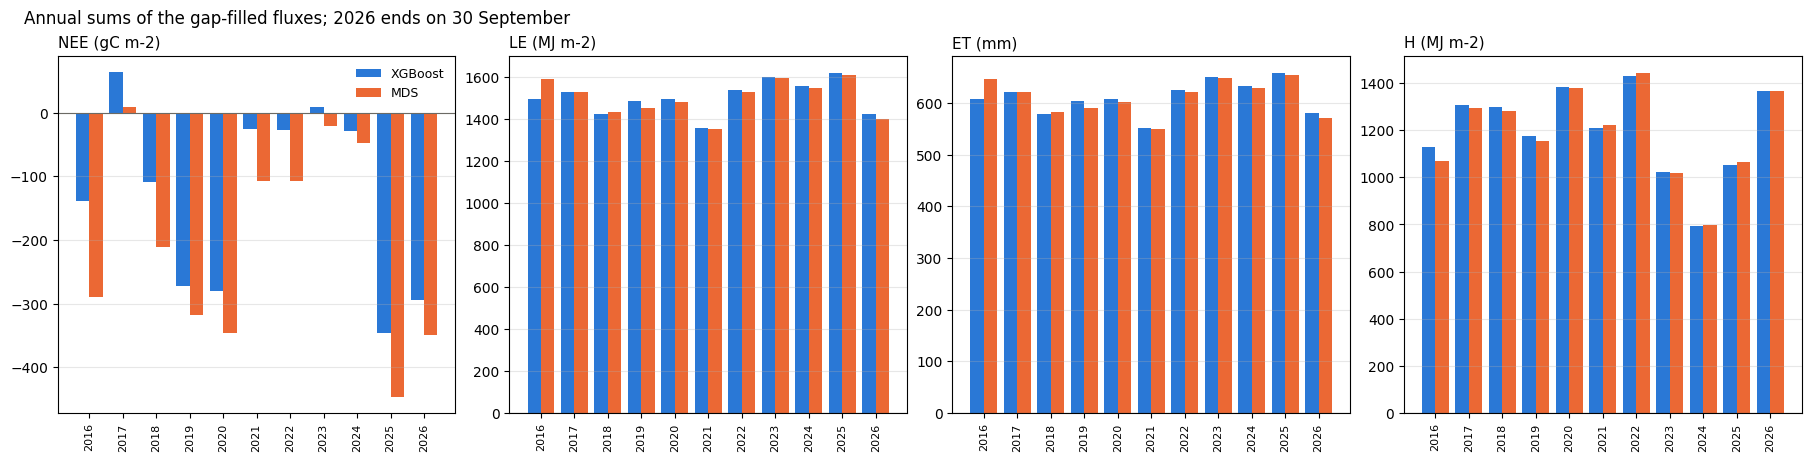

In [9]:
fig, axes = plt.subplots(1, len(MAIN), figsize=(18, 4.5), layout='constrained')
_years = ANNUAL.columns.to_numpy()
_colors = {'XGBoost': '#2a78d6', 'MDS': '#eb6834'}
for _ax, _var in zip(axes, MAIN):
    for _i, _mname in enumerate(METHODS):
        _ax.bar(np.arange(len(_years)) + (_i - 0.5) * 0.4, ANNUAL.loc[(_var, _mname)], 0.4,
                color=_colors[_mname], label=_mname)
    _ax.axhline(0, color='#6b6a64', lw=0.8)
    _ax.set_xticks(np.arange(len(_years)), _years, rotation=90, fontsize=8)
    _ax.set_title(_var, loc='left', fontsize=11)
    _ax.grid(axis='y', alpha=0.3)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle(f'Annual sums of the gap-filled fluxes; {_years[-1]} ends on {fullset.index[-1]:%d %B}',
             x=0.01, ha='left', fontsize=12)
plt.show()

## 💾 Export

The fullset as parquet, and next to it an `_INFO.md` file that lists every column with its source.

In [10]:
filepath = dv.save_parquet(data=fullset, filename=OUTNAME, outpath=OUTPATH)

_lines = [f"# {OUTNAME}", "",
          f"Fullset of the release FP2026.1, {fullset.index[0]} to {fullset.index[-1]} "
          f"({fullset.index.name}, UTC+01:00), {fullset.shape[0]:,} records x {fullset.shape[1]} columns.",
          f"Written {datetime.now():%Y-%m-%d %H:%M} by `{OUTNAME}.ipynb`.", "",
          "| source | file |", "|---|---|", f"| input | `{INPUTFILE}` |"]
_lines += [f"| {k} | `{v}` |" for k, v in FLUXFILES.items()]
for _name in ['input', *FLUXFILES]:
    _cols = [c for c, s in SOURCE.items() if s == _name]
    _lines += ["", f"## {_name} ({len(_cols)} columns)", ""] + [f"- `{c}`" for c in _cols]
with open(rf"{OUTPATH}\{OUTNAME}_INFO.md", "w", encoding="utf-8") as _f:
    _f.write("\n".join(_lines) + "\n")
print(f"Wrote {OUTPATH}\\{OUTNAME}_INFO.md")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\40_FULLSET\41_FUL
LSET_FP2026.1_2016-2026.09.parquet (3.872 seconds).

Wrote F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\40_FULLSET\41_FULLSET_FP2026.1_2016-2026.09_INFO.md


***

# End of notebook.

In [11]:
NOTEBOOK_END = datetime.now()
print(f"Runtime: {NOTEBOOK_END - NOTEBOOK_START}")

Runtime: 0:00:05.297041
